# 01 · Basic adversarial queueing networks

`aqnet` models queues where an attacker destroys or corrupts packets with probability `p`
and the sender retransmits after a timeout `T` (called `W` in the multi-node solvers).
Every topology has two tools:

* an **analytical solver** (`solve_*`) based on fixed-point traffic conservation, and
* a **SimPy simulator** (`simulate_*`) of the same system.

This notebook runs both for all five topologies and compares them.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import aqnet

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("aqnet", aqnet.__version__)

aqnet 0.3.0


## All five topologies, theory vs simulation

Each row uses the solver's default operating point. The simulated value is the mean of
four seeds, each run for 20 000 time units, so the numbers are reproducible.

In [2]:
SEEDS = range(4)
DUR = 20_000.0


def sim_mean(fn, **kw):
    vals = [fn(sim_duration=DUR, seed=s, **kw) for s in SEEDS]
    return float(np.mean(vals)), float(np.ptp(vals) / 2)


rows = []
kw = dict(lambda_n=2.0, p=0.2, mu=10.0, T=2.0)
rows.append(("1 one-node destruction", aqnet.solve_one_node_destruction(**kw),
             *sim_mean(aqnet.simulate_one_node_destruction, **kw)))
rows.append(("2 one-node modification", aqnet.solve_one_node_modification(**kw),
             *sim_mean(aqnet.simulate_one_node_modification, **kw)))

kw = dict(p=0.1, N=3, mu=2.0, lambda_arrival=0.15, W=8.0)
rows.append(("3 tandem (N=3)", aqnet.solve_tandem_theory(**kw), *sim_mean(aqnet.simulate_tandem, **kw)))

kw = dict(N=3, mu=2.0, lambda_arr=0.15, p=0.1, W=8.0)
rows.append(("4 feedforward (N=3)", aqnet.solve_feedforward_theory(**kw)[0],
             *sim_mean(aqnet.simulate_feedforward, **kw)))

kw = dict(N=5, mu=1.0, lambda_arr=0.05, p=0.1, W=50.0)
rows.append(("5 feedback mesh (N=5)", aqnet.solve_feedback_theory(**kw)[0],
             *sim_mean(aqnet.simulate_feedback, **kw)))

print(f"{'topology':<26}{'theory':>10}{'simulated':>18}{'rel. diff':>11}")
for name, th, sim, half in rows:
    print(f"{name:<26}{th:>10.4f}{sim:>11.4f} ± {half:.4f}{(sim - th) / th:>+11.2%}")

topology                      theory         simulated  rel. diff
1 one-node destruction        0.1388     0.1350 ± 0.0006     -2.70%
2 one-node modification       0.1667     0.1658 ± 0.0014     -0.50%
3 tandem (N=3)                2.2938     2.3201 ± 0.0485     +1.15%
4 feedforward (N=3)           2.0511     2.0356 ± 0.0550     -0.76%
5 feedback mesh (N=5)        10.0009    10.2174 ± 0.3104     +2.17%


Theory and simulation agree to within a few percent; `±` is half the spread across seeds.

## Delay versus load for the single-node cases

*Destruction* (Case 1) kills the packet before service, so the server only sees surviving
traffic. *Modification* (Case 2) corrupts the packet after it has been served, so every
failed attempt still costs a full service time. That difference shows up as much faster
delay growth for Case 2. Solvers return `inf` once no stable operating point exists.

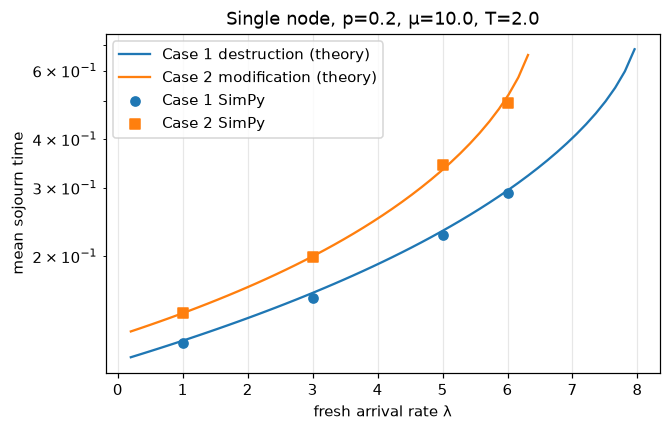

Case 1: λ_crit = 8.0796, last finite grid point λ = 7.9559
Case 2: λ_crit = 6.4636, last finite grid point λ = 6.3153
   λ   Case 1 sim vs theory   Case 2 sim vs theory   Case 2 runs collapsed
 1.0                 -1.46%                 +0.28%                   0 / 6
 3.0                 -3.12%                 -0.26%                   0 / 6
 5.0                 -2.24%                 +3.11%                   1 / 6
 6.0                 -1.77%                 -4.16%                   4 / 6


In [3]:
p, mu, T = 0.2, 10.0, 2.0
lams = np.linspace(0.2, 9.0, 60)
d_th = [aqnet.solve_one_node_destruction(lam, p, mu=mu, T=T) for lam in lams]
m_th = [aqnet.solve_one_node_modification(lam, p, mu=mu, T=T) for lam in lams]

lam_sim = [1.0, 3.0, 5.0, 6.0]


def runs(fn, lam):
    # A run that collapses into a retry storm records no successes and returns inf.
    vals = np.array([fn(lam, p, mu=mu, T=T, sim_duration=10_000.0, seed=s) for s in range(6)])
    ok = vals[np.isfinite(vals)]
    return (float(ok.mean()) if ok.size else np.nan), int((~np.isfinite(vals)).sum())


d_res = [runs(aqnet.simulate_one_node_destruction, lam) for lam in lam_sim]
m_res = [runs(aqnet.simulate_one_node_modification, lam) for lam in lam_sim]
d_sim = [r[0] for r in d_res]
m_sim = [r[0] for r in m_res]

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(lams, d_th, label="Case 1 destruction (theory)")
ax.plot(lams, m_th, label="Case 2 modification (theory)")
ax.scatter(lam_sim, d_sim, marker="o", zorder=3, label="Case 1 SimPy")
ax.scatter(lam_sim, m_sim, marker="s", zorder=3, label="Case 2 SimPy")
ax.set(xlabel="fresh arrival rate λ", ylabel="mean sojourn time", yscale="log",
       title=f"Single node, p={p}, μ={mu}, T={T}")
ax.legend()
plt.show()

for name, topo, curve in (("Case 1", "one_node_destruction", d_th), ("Case 2", "one_node_modification", m_th)):
    crit = aqnet.solve_saddle_node_bifurcation(topo, p=p, mu=mu, T=T).lambda_crit_sn
    last = lams[np.isfinite(curve)][-1]
    print(f"{name}: λ_crit = {crit:.4f}, last finite grid point λ = {last:.4f}")
print(f"{'λ':>4}{'Case 1 sim vs theory':>23}{'Case 2 sim vs theory':>23}{'Case 2 runs collapsed':>24}")
for lam, (d, _), (m, m_col) in zip(lam_sim, d_res, m_res):
    d_err = d / aqnet.solve_one_node_destruction(lam, p, mu=mu, T=T) - 1
    m_err = m / aqnet.solve_one_node_modification(lam, p, mu=mu, T=T) - 1
    print(f"{lam:>4}{d_err:>+23.2%}{m_err:>+23.2%}{m_col:>20} / 6")

* The theory curves end at the saddle-node limit `λ_crit` explained in notebook 03.
* Case 2 matches simulation closely. The Case 1 solver sits a few percent above simulation
  at mid load, and that gap does not shrink with longer runs, so it comes from the
  analytical approximation rather than simulation noise.
* Close to `λ_crit`, some long Case 2 runs **collapse** even though `λ < λ_crit`: a random
  burst of slow services pushes the retry load past the unstable fixed point and the queue
  never recovers (the simulator then reports `inf`; the plot averages the surviving runs).
  Notebook 02 explains this metastability.

## Longer chains

In a tandem chain every hop is attacked, so the end-to-end success probability falls like
`(1 - p)^N` and delay rises sharply with `N`.

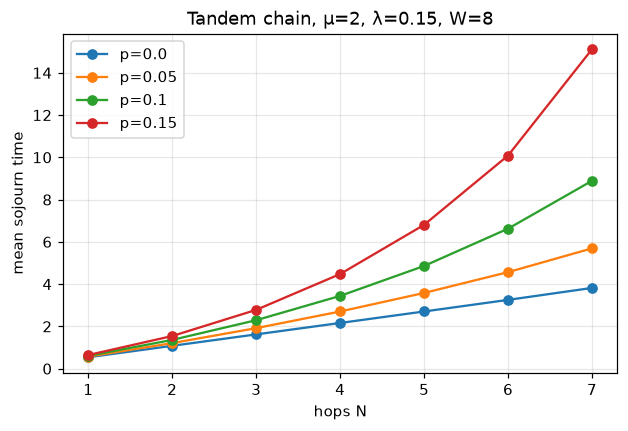

In [4]:
Ns = range(1, 8)
fig, ax = plt.subplots(figsize=(6.5, 4))
for p in (0.0, 0.05, 0.1, 0.15):
    ax.plot(list(Ns), [aqnet.solve_tandem_theory(p=p, N=n, mu=2.0, lambda_arrival=0.15, W=8.0) for n in Ns],
            marker="o", label=f"p={p}")
ax.set(xlabel="hops N", ylabel="mean sojourn time", title="Tandem chain, μ=2, λ=0.15, W=8")
ax.legend()
plt.show()